<a href="https://colab.research.google.com/github/oabdelhalim8/ML---10/blob/main/ML_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import sys

assert sys.version_info >= (3, 10)

In [2]:
IS_COLAB = "google.colab" in sys.modules
IS_KAGGLE = "kaggle_secrets" in sys.modules

In [3]:
if IS_COLAB:
    %pip install -q torchmetrics

In [4]:
from packaging.version import Version
import torch

assert Version(torch.__version__) >= Version("2.6.0")

In [5]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

device

'cpu'

In [6]:
if device == "cpu":
    print("Neural nets can be very slow without a hardware accelerator.")
    if IS_COLAB:
        print("Go to Runtime > Change runtime and select a GPU hardware "
              "accelerator.")
    if IS_KAGGLE:
        print("Go to Settings > Accelerator and select GPU.")

Neural nets can be very slow without a hardware accelerator.
Go to Runtime > Change runtime and select a GPU hardware accelerator.


In [7]:
import matplotlib.pyplot as plt

plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

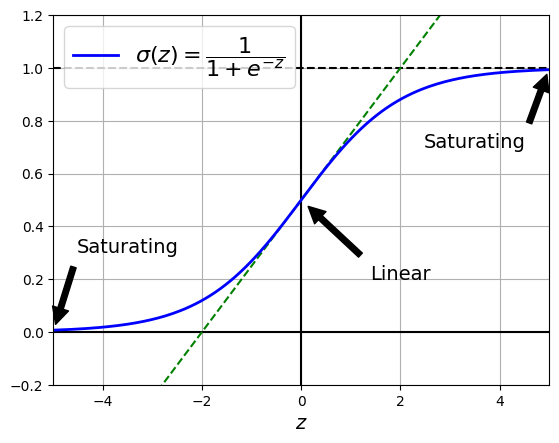

In [8]:
# extra code – this cell generates Figure 11–1

import numpy as np

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z = np.linspace(-5, 5, 200)

plt.plot([-5, 5], [0, 0], 'k-')
plt.plot([-5, 5], [1, 1], 'k--')
plt.plot([0, 0], [-0.2, 1.2], 'k-')
plt.plot([-5, 5], [-3/4, 7/4], 'g--')
plt.plot(z, sigmoid(z), "b-", linewidth=2,
         label=r"$\sigma(z) = \dfrac{1}{1+e^{-z}}$")
props = dict(facecolor='black', shrink=0.1)
plt.annotate('Saturating', xytext=(3.5, 0.7), xy=(5, 1), arrowprops=props,
             fontsize=14, ha="center")
plt.annotate('Saturating', xytext=(-3.5, 0.3), xy=(-5, 0), arrowprops=props,
             fontsize=14, ha="center")
plt.annotate('Linear', xytext=(2, 0.2), xy=(0, 0.5), arrowprops=props,
             fontsize=14, ha="center")
plt.grid(True)
plt.axis([-5, 5, -0.2, 1.2])
plt.xlabel("$z$")
plt.legend(loc="upper left", fontsize=16)

plt.show()

In [9]:
import torch
import torch.nn as nn

layer = nn.Linear(40, 10)
layer.weight.data *= 6 ** 0.5  # Kaiming init (or 3 ** 0.5 for LeCun init)
torch.zero_(layer.bias.data)

tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

In [10]:
layer = nn.Linear(40, 10)
nn.init.kaiming_uniform_(layer.weight)
nn.init.zeros_(layer.bias)

Parameter containing:
tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], requires_grad=True)

In [11]:
def use_he_init(module):
    if isinstance(module, nn.Linear):
        nn.init.kaiming_uniform_(module.weight)
        nn.init.zeros_(module.bias)

model = nn.Sequential(nn.Linear(50, 40), nn.ReLU(), nn.Linear(40, 1), nn.ReLU())
model.apply(use_he_init)

Sequential(
  (0): Linear(in_features=50, out_features=40, bias=True)
  (1): ReLU()
  (2): Linear(in_features=40, out_features=1, bias=True)
  (3): ReLU()
)

In [12]:
model = nn.Sequential(nn.Linear(50, 40), nn.LeakyReLU(negative_slope=0.2))
model.apply(use_he_init)

Sequential(
  (0): Linear(in_features=50, out_features=40, bias=True)
  (1): LeakyReLU(negative_slope=0.2)
)

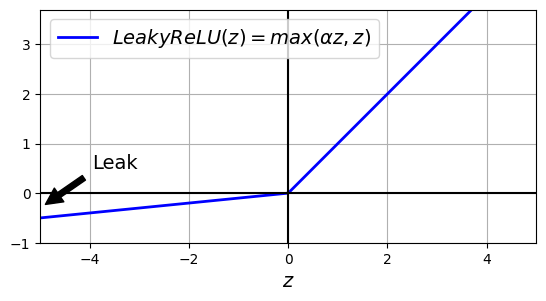

In [13]:
# extra code – this cell generates Figure 11–2

def leaky_relu(z, alpha):
    return np.maximum(alpha * z, z)

z = np.linspace(-5, 5, 200)
plt.plot(z, leaky_relu(z, 0.1), "b-", linewidth=2, label=r"$LeakyReLU(z) = max(\alpha z, z)$")
plt.plot([-5, 5], [0, 0], 'k-')
plt.plot([0, 0], [-1, 3.7], 'k-')
plt.grid(True)
props = dict(facecolor='black', shrink=0.1)
plt.annotate('Leak', xytext=(-3.5, 0.5), xy=(-5, -0.3), arrowprops=props,
             fontsize=14, ha="center")
plt.xlabel("$z$")
plt.axis([-5, 5, -1, 3.7])
plt.gca().set_aspect("equal")
plt.legend()

plt.show()

In [14]:
torch.manual_seed(42)
alpha = 0.2
model = nn.Sequential(nn.Linear(50, 40), nn.LeakyReLU(negative_slope=alpha))
nn.init.kaiming_uniform_(model[0].weight, alpha, nonlinearity="leaky_relu")
model(torch.rand(2, 50)).shape

torch.Size([2, 40])

In [15]:
torch.manual_seed(42)
model = nn.Sequential(nn.Linear(50, 40), nn.ELU())
nn.init.kaiming_uniform_(model[0].weight)
model(torch.rand(2, 50)).shape

torch.Size([2, 40])

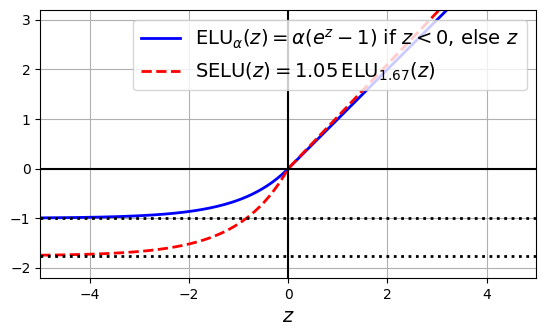

In [16]:
# extra code – this cell generates Figure 11–3

from scipy.special import erfc

# alpha and scale to self normalize with mean 0 and standard deviation 1
# (see equation 14 in the paper):
alpha_0_1 = -np.sqrt(2 / np.pi) / (erfc(1 / np.sqrt(2)) * np.exp(1 / 2) - 1)
scale_0_1 = (
    (1 - erfc(1 / np.sqrt(2)) * np.sqrt(np.e))
    * np.sqrt(2 * np.pi)
    * (
        2 * erfc(np.sqrt(2)) * np.e ** 2
        + np.pi * erfc(1 / np.sqrt(2)) ** 2 * np.e
        - 2 * (2 + np.pi) * erfc(1 / np.sqrt(2)) * np.sqrt(np.e)
        + np.pi
        + 2
    ) ** (-1 / 2)
)

def elu(z, alpha=1):
    return np.where(z < 0, alpha * (np.exp(z) - 1), z)

def selu(z, scale=scale_0_1, alpha=alpha_0_1):
    return scale * elu(z, alpha)

z = np.linspace(-5, 5, 200)
plt.plot(z, elu(z), "b-", linewidth=2, label=r"ELU$_\alpha(z) = \alpha (e^z - 1)$ if $z < 0$, else $z$")
plt.plot(z, selu(z), "r--", linewidth=2, label=r"SELU$(z) = 1.05 \, $ELU$_{1.67}(z)$")
plt.plot([-5, 5], [0, 0], 'k-')
plt.plot([-5, 5], [-1, -1], 'k:', linewidth=2)
plt.plot([-5, 5], [-1.758, -1.758], 'k:', linewidth=2)
plt.plot([0, 0], [-2.2, 3.2], 'k-')
plt.grid(True)
plt.axis([-5, 5, -2.2, 3.2])
plt.xlabel("$z$")
plt.gca().set_aspect("equal")
plt.legend()

plt.show()

In [17]:
torch.manual_seed(42)
model = nn.Sequential(nn.Linear(50, 40), nn.SELU())
nn.init.kaiming_uniform_(model[0].weight)
model(torch.rand(2, 50)).shape

torch.Size([2, 40])

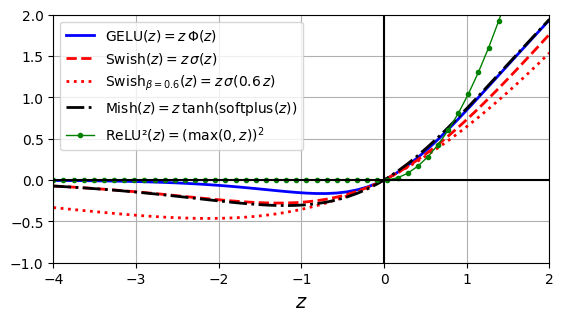

In [18]:
# extra code – this cell generates Figure 11–4

def swish(z, beta=1):
    return z * sigmoid(beta * z)

def approx_gelu(z):
    return swish(z, beta=1.702)

def softplus(z):
    return np.log(1 + np.exp(z))

def mish(z):
    return z * np.tanh(softplus(z))

def relu_squared(z):
    return np.maximum(0, z)**2

z = np.linspace(-4, 2, 50)

beta = 0.6
plt.plot(z, approx_gelu(z), "b-", linewidth=2,
         label=r"GELU$(z) = z\,\Phi(z)$")
plt.plot(z, swish(z), "r--", linewidth=2,
         label=r"Swish$(z) = z\,\sigma(z)$")
plt.plot(z, swish(z, beta), "r:", linewidth=2,
         label=fr"Swish$_{{\beta={beta}}}(z)=z\,\sigma({beta}\,z)$")
plt.plot(z, mish(z), "k-.", linewidth=2,
         label=fr"Mish$(z) = z\,\tanh($softplus$(z))$")
plt.plot(z, relu_squared(z), "g.-", linewidth=1,
         label=fr"ReLU²$(z) = (\max(0, z))^2$")
plt.plot([-4, 2], [0, 0], 'k-')
plt.plot([0, 0], [-2.2, 3.2], 'k-')
plt.grid(True)
plt.axis([-4, 2, -1, 2])
plt.gca().set_aspect("equal")
plt.xlabel("$z$")
#plt.legend(loc="upper left")
plt.legend(loc="upper left", fontsize=10)

plt.show()

In [19]:
class SwiGLU(nn.Module):
    def __init__(self, beta=1.0):
        super().__init__()
        self.beta = beta

    def forward(self, x):
        z1, z2 = x.chunk(2, dim=-1)
        param_swish = z1 * torch.sigmoid(self.beta * z1)
        return param_swish * z2

torch.manual_seed(42)
model = nn.Sequential(nn.Linear(50, 2 * 40), SwiGLU(beta=0.2))
nn.init.kaiming_uniform_(model[0].weight)
model(torch.rand(2, 50)).shape

torch.Size([2, 40])

In [20]:
import torch.nn.functional as F

class ReLU2(nn.Module):
    def forward(self, x):
        return F.relu(x).square()

torch.manual_seed(42)
model = nn.Sequential(nn.Linear(50, 40), ReLU2())
nn.init.kaiming_uniform_(model[0].weight)
model(torch.rand(2, 50)).shape

torch.Size([2, 40])

In [21]:
torch.manual_seed(42)

model = nn.Sequential(
    nn.Flatten(),
    nn.BatchNorm1d(1 * 28 * 28),
    nn.Linear(1 * 28 * 28, 300),
    nn.ReLU(),
    nn.BatchNorm1d(300),
    nn.Linear(300, 100),
    nn.ReLU(),
    nn.BatchNorm1d(100),
    nn.Linear(100, 10)
)

In [22]:
dict(model[1].named_parameters()).keys()

dict_keys(['weight', 'bias'])

In [23]:
dict(model[1].named_buffers()).keys()

dict_keys(['running_mean', 'running_var', 'num_batches_tracked'])

In [24]:
torch.manual_seed(42)

model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(1 * 28 * 28, 300, bias=False),
    nn.BatchNorm1d(300),
    nn.ReLU(),
    nn.Linear(300, 100, bias=False),
    nn.BatchNorm1d(100),
    nn.ReLU(),
    nn.Linear(100, 10)
)

In [25]:
torch.manual_seed(42)

inputs = torch.randn(32, 3, 100, 200)  # a batch of random RGB images
layer_norm = nn.LayerNorm([100, 200])
result = layer_norm(inputs)  # normalizes over the last two dimensions

In [26]:
means = inputs.mean(dim=[2, 3], keepdim=True)
vars_ = inputs.var(dim=[2, 3], keepdim=True, unbiased=False)
stds = torch.sqrt(vars_ + layer_norm.eps)
result2 = layer_norm.weight * (inputs - means) / stds + layer_norm.bias
assert torch.allclose(result, result2)

In [27]:
layer_norm = nn.LayerNorm([3, 100, 200])
result = layer_norm(inputs)  # normalizes over the last three dimensions

In [28]:
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import fetch_openml

fashion_mnist = fetch_openml(name="Fashion-MNIST", as_frame=False)
X = torch.FloatTensor(fashion_mnist.data.reshape(-1, 1, 28, 28) / 255.)
y = torch.from_numpy(fashion_mnist.target.astype(int))
in_B = (y == 0) | (y == 2)  # Pullover or T-shirt/top
X_A, y_A = X[~in_B], y[~in_B]
y_A = torch.maximum(y_A - 2, torch.tensor(0))  # [1,3,4,5,6,7,8,9] => [0,..,7]
X_B, y_B = X[in_B], (y[in_B] == 2).to(dtype=torch.float32).view(-1, 1)

train_set_A = TensorDataset(X_A[:-7_000], y_A[:-7000])
valid_set_A = TensorDataset(X_A[-7_000:-5000], y_A[-7000:-5000])
test_set_A = TensorDataset(X_A[-5_000:], y_A[-5000:])
train_set_B = TensorDataset(X_B[:20], y_B[:20])
valid_set_B = TensorDataset(X_B[20:5000], y_B[20:5000])
test_set_B = TensorDataset(X_B[5_000:], y_B[5000:])

train_loader_A = DataLoader(train_set_A, batch_size=32, shuffle=True)
valid_loader_A = DataLoader(valid_set_A, batch_size=32)
test_loader_A = DataLoader(test_set_A, batch_size=32)
train_loader_B = DataLoader(train_set_B, batch_size=32, shuffle=True)
valid_loader_B = DataLoader(valid_set_B, batch_size=32)
test_loader_B = DataLoader(test_set_B, batch_size=32)

In [29]:
import torchmetrics

def evaluate_tm(model, data_loader, metric):
    model.eval()
    metric.reset()
    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            metric.update(y_pred, y_batch)
    return metric.compute()

def train(model, optimizer, loss_fn, metric, train_loader, valid_loader,
          n_epochs):
    history = {"train_losses": [], "train_metrics": [], "valid_metrics": []}
    for epoch in range(n_epochs):
        total_loss = 0.0
        metric.reset()
        model.train()
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
            total_loss += loss.item()
            loss.backward()
            # Uncomment to activate gradient clipping:
            #nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            optimizer.zero_grad()
            metric.update(y_pred, y_batch)
        history["train_losses"].append(total_loss / len(train_loader))
        history["train_metrics"].append(metric.compute().item())
        history["valid_metrics"].append(
            evaluate_tm(model, valid_loader, metric).item())
        print(f"Epoch {epoch + 1}/{n_epochs}, "
              f"train loss: {history['train_losses'][-1]:.4f}, "
              f"train metric: {history['train_metrics'][-1]:.4f}, "
              f"valid metric: {history['valid_metrics'][-1]:.4f}")
    return history

In [30]:
torch.manual_seed(42)

model_A = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 100),
    nn.ReLU(),
    nn.Linear(100, 100),
    nn.ReLU(),
    nn.Linear(100, 100),
    nn.ReLU(),
    nn.Linear(100, 8)
)
model_A = model_A.to(device)

In [31]:
model_A.apply(use_he_init)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=100, bias=True)
  (2): ReLU()
  (3): Linear(in_features=100, out_features=100, bias=True)
  (4): ReLU()
  (5): Linear(in_features=100, out_features=100, bias=True)
  (6): ReLU()
  (7): Linear(in_features=100, out_features=8, bias=True)
)

In [32]:
n_epochs = 20
optimizer = torch.optim.SGD(model_A.parameters(), lr=0.005)
xentropy = nn.CrossEntropyLoss()
accuracy = torchmetrics.Accuracy(task="multiclass", num_classes=8).to(device)
history_A = train(model_A, optimizer, xentropy, accuracy,
                  train_loader_A, valid_loader_A, n_epochs)

Epoch 1/20, train loss: 0.5995, train metric: 0.7997, valid metric: 0.8695
Epoch 2/20, train loss: 0.3416, train metric: 0.8807, valid metric: 0.8920
Epoch 3/20, train loss: 0.2961, train metric: 0.8970, valid metric: 0.8940
Epoch 4/20, train loss: 0.2715, train metric: 0.9065, valid metric: 0.9030
Epoch 5/20, train loss: 0.2571, train metric: 0.9106, valid metric: 0.8965
Epoch 6/20, train loss: 0.2430, train metric: 0.9155, valid metric: 0.9040
Epoch 7/20, train loss: 0.2328, train metric: 0.9192, valid metric: 0.9030
Epoch 8/20, train loss: 0.2243, train metric: 0.9234, valid metric: 0.9070
Epoch 9/20, train loss: 0.2164, train metric: 0.9242, valid metric: 0.9080
Epoch 10/20, train loss: 0.2097, train metric: 0.9270, valid metric: 0.9100
Epoch 11/20, train loss: 0.2043, train metric: 0.9285, valid metric: 0.9085
Epoch 12/20, train loss: 0.1979, train metric: 0.9305, valid metric: 0.9130
Epoch 13/20, train loss: 0.1923, train metric: 0.9319, valid metric: 0.9075
Epoch 14/20, train lo

In [33]:
torch.manual_seed(9)

model_B = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 100),
    nn.ReLU(),
    nn.Linear(100, 100),
    nn.ReLU(),
    nn.Linear(100, 100),
    nn.ReLU(),
    nn.Linear(100, 1)
).to(device)

In [34]:
model_B.apply(use_he_init)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=100, bias=True)
  (2): ReLU()
  (3): Linear(in_features=100, out_features=100, bias=True)
  (4): ReLU()
  (5): Linear(in_features=100, out_features=100, bias=True)
  (6): ReLU()
  (7): Linear(in_features=100, out_features=1, bias=True)
)

In [35]:
n_epochs = 20
optimizer = torch.optim.SGD(model_B.parameters(), lr=0.005)
xentropy = nn.BCEWithLogitsLoss()
accuracy = torchmetrics.Accuracy(task="binary").to(device)
history_B = train(model_B, optimizer, xentropy, accuracy,
                  train_loader_B, valid_loader_B, n_epochs)

Epoch 1/20, train loss: 0.7413, train metric: 0.6000, valid metric: 0.4639
Epoch 2/20, train loss: 0.7117, train metric: 0.6000, valid metric: 0.4833
Epoch 3/20, train loss: 0.6846, train metric: 0.6500, valid metric: 0.5191
Epoch 4/20, train loss: 0.6608, train metric: 0.6500, valid metric: 0.5592
Epoch 5/20, train loss: 0.6391, train metric: 0.6500, valid metric: 0.6032
Epoch 6/20, train loss: 0.6186, train metric: 0.7500, valid metric: 0.6402
Epoch 7/20, train loss: 0.5986, train metric: 0.8000, valid metric: 0.6805
Epoch 8/20, train loss: 0.5795, train metric: 0.8500, valid metric: 0.7135
Epoch 9/20, train loss: 0.5621, train metric: 0.8500, valid metric: 0.7382
Epoch 10/20, train loss: 0.5457, train metric: 0.9000, valid metric: 0.7627
Epoch 11/20, train loss: 0.5303, train metric: 0.9000, valid metric: 0.7797
Epoch 12/20, train loss: 0.5158, train metric: 0.9000, valid metric: 0.7956
Epoch 13/20, train loss: 0.5024, train metric: 0.9000, valid metric: 0.8092
Epoch 14/20, train lo

In [36]:
evaluate_tm(model_B, test_loader_B, accuracy)

tensor(0.8652)

In [37]:
import copy

torch.manual_seed(43)
reused_layers = copy.deepcopy(model_A[:-1])
model_B_on_A = nn.Sequential(
    *reused_layers,
    nn.Linear(100, 1)  # new output layer for task B
).to(device)

In [38]:
for layer in model_B_on_A[:-1]:
    for param in layer.parameters():
        param.requires_grad = False

In [39]:
n_epochs = 10
optimizer = torch.optim.SGD(model_B_on_A.parameters(), lr=0.005)
xentropy = nn.BCEWithLogitsLoss()
accuracy = torchmetrics.Accuracy(task="binary").to(device)
history_B = train(model_B_on_A, optimizer, xentropy, accuracy,
                  train_loader_B, valid_loader_B, n_epochs)

Epoch 1/10, train loss: 0.7859, train metric: 0.1500, valid metric: 0.3910
Epoch 2/10, train loss: 0.7604, train metric: 0.2500, valid metric: 0.4241
Epoch 3/10, train loss: 0.7371, train metric: 0.4000, valid metric: 0.4490
Epoch 4/10, train loss: 0.7155, train metric: 0.4500, valid metric: 0.4769
Epoch 5/10, train loss: 0.6950, train metric: 0.5000, valid metric: 0.5026
Epoch 6/10, train loss: 0.6756, train metric: 0.5500, valid metric: 0.5309
Epoch 7/10, train loss: 0.6572, train metric: 0.7000, valid metric: 0.5649
Epoch 8/10, train loss: 0.6398, train metric: 0.7000, valid metric: 0.5984
Epoch 9/10, train loss: 0.6232, train metric: 0.7000, valid metric: 0.6343
Epoch 10/10, train loss: 0.6075, train metric: 0.7000, valid metric: 0.6725


In [40]:
for layer in model_B_on_A[2:]:
    for param in layer.parameters():
        param.requires_grad = True

In [41]:
n_epochs = 20
optimizer = torch.optim.SGD(model_B_on_A.parameters(), lr=0.005)
xentropy = nn.BCEWithLogitsLoss()
accuracy = torchmetrics.Accuracy(task="binary").to(device)
history_B = train(model_B_on_A, optimizer, xentropy, accuracy,
                  train_loader_B, valid_loader_B, n_epochs)

Epoch 1/20, train loss: 0.5925, train metric: 0.7500, valid metric: 0.7127
Epoch 2/20, train loss: 0.5750, train metric: 0.7500, valid metric: 0.7480
Epoch 3/20, train loss: 0.5585, train metric: 0.8500, valid metric: 0.7781
Epoch 4/20, train loss: 0.5429, train metric: 0.8500, valid metric: 0.8042
Epoch 5/20, train loss: 0.5281, train metric: 0.8500, valid metric: 0.8229
Epoch 6/20, train loss: 0.5141, train metric: 0.8500, valid metric: 0.8386
Epoch 7/20, train loss: 0.5008, train metric: 0.9000, valid metric: 0.8514
Epoch 8/20, train loss: 0.4881, train metric: 0.9000, valid metric: 0.8608
Epoch 9/20, train loss: 0.4761, train metric: 0.9000, valid metric: 0.8703
Epoch 10/20, train loss: 0.4646, train metric: 0.9000, valid metric: 0.8761
Epoch 11/20, train loss: 0.4537, train metric: 0.9500, valid metric: 0.8825
Epoch 12/20, train loss: 0.4433, train metric: 0.9500, valid metric: 0.8896
Epoch 13/20, train loss: 0.4334, train metric: 0.9500, valid metric: 0.8922
Epoch 14/20, train lo

In [42]:
evaluate_tm(model_B_on_A, test_loader_B, accuracy)

tensor(0.9134)

In [43]:
# extra code – a little function to test an optimizer on Fashion MNIST

train_set = TensorDataset(X[:55_000], y[:55_000])
valid_set = TensorDataset(X[55_000:60_000], y[55_000:60_000])
test_set = TensorDataset(X[60_000:], y[60_000:])

def build_model(seed=42):
    torch.manual_seed(seed)
    model = nn.Sequential(
        nn.Flatten(),
        nn.Linear(28 * 28, 100),
        nn.ReLU(),
        nn.Linear(100, 100),
        nn.ReLU(),
        nn.Linear(100, 100),
        nn.ReLU(),
        nn.Linear(100, 10)
    ).to(device)
    model.apply(use_he_init)
    return model

def test_optimizer(model, optimizer, n_epochs=10, batch_size=32):
    train_loader = DataLoader(train_set, batch_size=32, shuffle=True)
    valid_loader = DataLoader(valid_set, batch_size=32)
    test_loader = DataLoader(test_set, batch_size=32)
    xentropy = nn.CrossEntropyLoss()
    accuracy = torchmetrics.Accuracy(task="multiclass", num_classes=10)
    history = train(model, optimizer, xentropy, accuracy.to(device),
                    train_loader, valid_loader, n_epochs)
    return history, evaluate_tm(model, test_loader, accuracy)

In [44]:
model = build_model()  # extra code
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)
history_sgd, acc_sgd = test_optimizer(model, optimizer)  # extra code

Epoch 1/10, train loss: 0.5620, train metric: 0.7960, valid metric: 0.8504
Epoch 2/10, train loss: 0.4009, train metric: 0.8529, valid metric: 0.8340
Epoch 3/10, train loss: 0.3620, train metric: 0.8661, valid metric: 0.8718
Epoch 4/10, train loss: 0.3369, train metric: 0.8743, valid metric: 0.8742
Epoch 5/10, train loss: 0.3184, train metric: 0.8815, valid metric: 0.8562
Epoch 6/10, train loss: 0.3013, train metric: 0.8886, valid metric: 0.8816
Epoch 7/10, train loss: 0.2906, train metric: 0.8921, valid metric: 0.8716
Epoch 8/10, train loss: 0.2790, train metric: 0.8956, valid metric: 0.8858
Epoch 9/10, train loss: 0.2701, train metric: 0.8986, valid metric: 0.8664
Epoch 10/10, train loss: 0.2611, train metric: 0.9020, valid metric: 0.8742


In [45]:
model = build_model()  # extra code
optimizer = torch.optim.SGD(model.parameters(), momentum=0.9, lr=0.05)
history_momentum, acc_momentum = test_optimizer(model, optimizer)  # extra code

Epoch 1/10, train loss: 0.6205, train metric: 0.7750, valid metric: 0.8292
Epoch 2/10, train loss: 0.4802, train metric: 0.8280, valid metric: 0.8430
Epoch 3/10, train loss: 0.4413, train metric: 0.8431, valid metric: 0.8378
Epoch 4/10, train loss: 0.4249, train metric: 0.8489, valid metric: 0.8428
Epoch 5/10, train loss: 0.4137, train metric: 0.8531, valid metric: 0.8614
Epoch 6/10, train loss: 0.4011, train metric: 0.8577, valid metric: 0.8496
Epoch 7/10, train loss: 0.3853, train metric: 0.8630, valid metric: 0.8638
Epoch 8/10, train loss: 0.3833, train metric: 0.8625, valid metric: 0.8518
Epoch 9/10, train loss: 0.3760, train metric: 0.8668, valid metric: 0.8432
Epoch 10/10, train loss: 0.3787, train metric: 0.8657, valid metric: 0.8490


In [46]:
model = build_model()  # extra code
optimizer = torch.optim.SGD(model.parameters(),
                            momentum=0.9, nesterov=True, lr=0.05)
history_nesterov, acc_nesterov = test_optimizer(model, optimizer)  # extra code

Epoch 1/10, train loss: 0.5645, train metric: 0.7937, valid metric: 0.8216
Epoch 2/10, train loss: 0.4428, train metric: 0.8409, valid metric: 0.8470
Epoch 3/10, train loss: 0.4115, train metric: 0.8518, valid metric: 0.8476
Epoch 4/10, train loss: 0.3986, train metric: 0.8571, valid metric: 0.8510
Epoch 5/10, train loss: 0.3851, train metric: 0.8635, valid metric: 0.8490
Epoch 6/10, train loss: 0.3684, train metric: 0.8694, valid metric: 0.8600
Epoch 7/10, train loss: 0.3610, train metric: 0.8710, valid metric: 0.8634
Epoch 8/10, train loss: 0.3524, train metric: 0.8745, valid metric: 0.8644
Epoch 9/10, train loss: 0.3492, train metric: 0.8758, valid metric: 0.8556
Epoch 10/10, train loss: 0.3404, train metric: 0.8773, valid metric: 0.8580


In [47]:
model = build_model()  # extra code
optimizer = torch.optim.Adagrad(model.parameters(), lr=0.05)
history_adagrad, acc_adagrad = test_optimizer(model, optimizer)  # extra code

Epoch 1/10, train loss: 0.5657, train metric: 0.8089, valid metric: 0.8396
Epoch 2/10, train loss: 0.3703, train metric: 0.8639, valid metric: 0.8460
Epoch 3/10, train loss: 0.3357, train metric: 0.8761, valid metric: 0.8726
Epoch 4/10, train loss: 0.3149, train metric: 0.8837, valid metric: 0.8740
Epoch 5/10, train loss: 0.2996, train metric: 0.8893, valid metric: 0.8752
Epoch 6/10, train loss: 0.2852, train metric: 0.8945, valid metric: 0.8762
Epoch 7/10, train loss: 0.2761, train metric: 0.8975, valid metric: 0.8822
Epoch 8/10, train loss: 0.2666, train metric: 0.8999, valid metric: 0.8832
Epoch 9/10, train loss: 0.2584, train metric: 0.9034, valid metric: 0.8690
Epoch 10/10, train loss: 0.2514, train metric: 0.9065, valid metric: 0.8768


In [48]:
model = build_model()  # extra code
optimizer = torch.optim.RMSprop(model.parameters(), alpha=0.9, lr=0.05)
history_rmsprop, acc_rmsprop = test_optimizer(model, optimizer)  # extra code

Epoch 1/10, train loss: 2.6893, train metric: 0.4509, valid metric: 0.4378
Epoch 2/10, train loss: 1.4809, train metric: 0.4389, valid metric: 0.4064
Epoch 3/10, train loss: 1.4620, train metric: 0.4479, valid metric: 0.5188
Epoch 4/10, train loss: 1.4779, train metric: 0.4543, valid metric: 0.4380
Epoch 5/10, train loss: 1.3997, train metric: 0.4440, valid metric: 0.2884
Epoch 6/10, train loss: 1.5003, train metric: 0.4242, valid metric: 0.4456
Epoch 7/10, train loss: 1.5026, train metric: 0.4280, valid metric: 0.3734
Epoch 8/10, train loss: 1.4916, train metric: 0.4219, valid metric: 0.4474
Epoch 9/10, train loss: 1.4471, train metric: 0.4213, valid metric: 0.4090
Epoch 10/10, train loss: 1.4840, train metric: 0.4127, valid metric: 0.4110


In [49]:
model = build_model()  # extra code
optimizer = torch.optim.Adam(model.parameters(), betas=(0.9, 0.999), lr=0.05)
history_adam, acc_adam = test_optimizer(model, optimizer)  # extra code

Epoch 1/10, train loss: 1.1870, train metric: 0.5547, valid metric: 0.4884
Epoch 2/10, train loss: 1.3970, train metric: 0.4113, valid metric: 0.4474
Epoch 3/10, train loss: 1.2323, train metric: 0.4735, valid metric: 0.4712
Epoch 4/10, train loss: 1.3806, train metric: 0.4306, valid metric: 0.4438
Epoch 5/10, train loss: 1.3522, train metric: 0.4324, valid metric: 0.4240
Epoch 6/10, train loss: 1.1814, train metric: 0.4967, valid metric: 0.4812
Epoch 7/10, train loss: 1.2457, train metric: 0.4738, valid metric: 0.4602
Epoch 8/10, train loss: 1.3018, train metric: 0.4305, valid metric: 0.4058
Epoch 9/10, train loss: 1.3203, train metric: 0.4090, valid metric: 0.4204
Epoch 10/10, train loss: 1.3297, train metric: 0.4069, valid metric: 0.4294


In [50]:
model = build_model()  # extra code
optimizer = torch.optim.Adamax(model.parameters(), betas=(0.9, 0.999), lr=0.05)
history_adamax, acc_adamax = test_optimizer(model, optimizer)  # extra code

Epoch 1/10, train loss: 0.6380, train metric: 0.7830, valid metric: 0.8120
Epoch 2/10, train loss: 0.4743, train metric: 0.8304, valid metric: 0.8384
Epoch 3/10, train loss: 0.4412, train metric: 0.8430, valid metric: 0.8376
Epoch 4/10, train loss: 0.4194, train metric: 0.8491, valid metric: 0.8608
Epoch 5/10, train loss: 0.4060, train metric: 0.8560, valid metric: 0.8596
Epoch 6/10, train loss: 0.3921, train metric: 0.8604, valid metric: 0.8490
Epoch 7/10, train loss: 0.3811, train metric: 0.8660, valid metric: 0.8612
Epoch 8/10, train loss: 0.3774, train metric: 0.8667, valid metric: 0.8538
Epoch 9/10, train loss: 0.3734, train metric: 0.8674, valid metric: 0.8532
Epoch 10/10, train loss: 0.3624, train metric: 0.8716, valid metric: 0.8444


In [51]:
model = build_model()  # extra code
optimizer = torch.optim.NAdam(model.parameters(), betas=(0.9, 0.999), lr=0.05)
history_nadam, acc_nadam = test_optimizer(model, optimizer)  # extra code

Epoch 1/10, train loss: 1.3337, train metric: 0.4827, valid metric: 0.1944
Epoch 2/10, train loss: 1.8954, train metric: 0.1871, valid metric: 0.1986
Epoch 3/10, train loss: 1.7566, train metric: 0.1936, valid metric: 0.1942
Epoch 4/10, train loss: 1.7300, train metric: 0.1965, valid metric: 0.1926
Epoch 5/10, train loss: 1.7585, train metric: 0.1973, valid metric: 0.1938
Epoch 6/10, train loss: 1.7147, train metric: 0.1973, valid metric: 0.1952
Epoch 7/10, train loss: 1.7149, train metric: 0.1995, valid metric: 0.1906
Epoch 8/10, train loss: 1.7240, train metric: 0.1973, valid metric: 0.2060
Epoch 9/10, train loss: 1.7486, train metric: 0.1975, valid metric: 0.1914
Epoch 10/10, train loss: 1.7389, train metric: 0.1960, valid metric: 0.1990


In [52]:
model = build_model()  # extra code
optimizer = torch.optim.AdamW(model.parameters(), betas=(0.9, 0.999),
                              weight_decay=1e-5, lr=0.05)
history_adamw, acc_adamw = test_optimizer(model, optimizer)

Epoch 1/10, train loss: 1.1376, train metric: 0.5890, valid metric: 0.4626
Epoch 2/10, train loss: 1.3734, train metric: 0.4267, valid metric: 0.4476
Epoch 3/10, train loss: 1.3555, train metric: 0.4299, valid metric: 0.4102
Epoch 4/10, train loss: 1.3595, train metric: 0.4097, valid metric: 0.4834
Epoch 5/10, train loss: 1.2418, train metric: 0.4760, valid metric: 0.4596
Epoch 6/10, train loss: 1.2898, train metric: 0.4418, valid metric: 0.4382
Epoch 7/10, train loss: 1.3163, train metric: 0.4306, valid metric: 0.4492
Epoch 8/10, train loss: 1.3161, train metric: 0.4293, valid metric: 0.4468
Epoch 9/10, train loss: 1.3914, train metric: 0.4017, valid metric: 0.4286
Epoch 10/10, train loss: 1.3769, train metric: 0.4160, valid metric: 0.4168


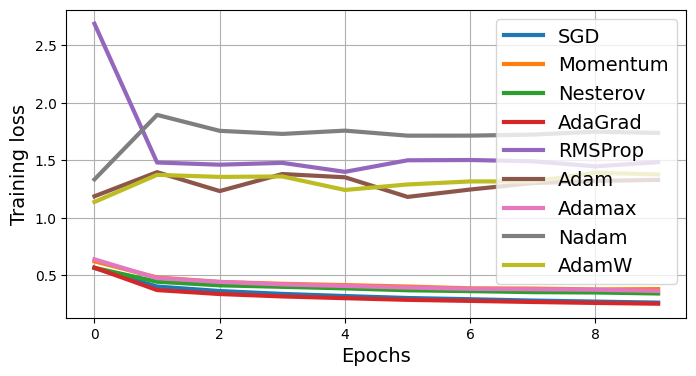

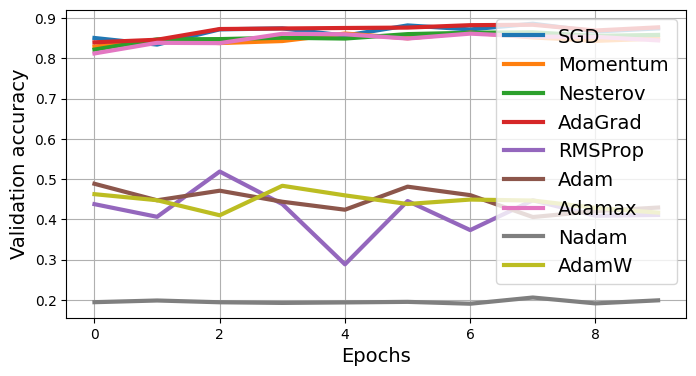

In [53]:
# extra code – visualize the learning curves of all the optimizers

for plot in ("train_losses", "valid_metrics"):
    plt.figure(figsize=(8, 4))
    opt_names = "SGD Momentum Nesterov AdaGrad RMSProp Adam Adamax Nadam AdamW"
    for history, opt_name in zip(
        (history_sgd, history_momentum, history_nesterov, history_adagrad,
         history_rmsprop, history_adam, history_adamax, history_nadam,
         history_adamw), opt_names.split()):
        plt.plot(history[plot], label=opt_name, linewidth=3)

    plt.grid()
    plt.xlabel("Epochs")
    plt.ylabel({"train_losses": "Training loss", "valid_metrics": "Validation accuracy"}[plot])
    plt.legend(loc="upper right")
    plt.show()

In [54]:
model = build_model()  # extra code
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)  # or any other optim.
exp_scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.9)

In [55]:
def train_with_scheduler(model, optimizer, loss_fn, metric, train_loader,
                         valid_loader, n_epochs, scheduler):
    history = {"train_losses": [], "train_metrics": [], "valid_metrics": []}
    for epoch in range(n_epochs):
        losses = []
        metric.reset()
        for X_batch, y_batch in train_loader:
            model.train()
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
            losses.append(loss.item())
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            metric.update(y_pred, y_batch)
        history["train_losses"].append(np.mean(losses))
        history["train_metrics"].append(metric.compute().item())
        val_metric = evaluate_tm(model, valid_loader, metric).item()
        history["valid_metrics"].append(val_metric)
        print(f"Epoch {epoch + 1}/{n_epochs}, "
              f"train loss: {history['train_losses'][-1]:.4f}, "
              f"train metric: {history['train_metrics'][-1]:.4f}, "
              f"valid metric: {history['valid_metrics'][-1]:.4f}")
        if isinstance(scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau):
            scheduler.step(val_metric)
        else:
            scheduler.step()
        print(f"Learning rate: {scheduler.get_last_lr()[0]:.5f}")
    return history

def test_scheduler(model, optimizer, scheduler, n_epochs=10, batch_size=32):
    train_loader = DataLoader(train_set, batch_size=32, shuffle=True)
    valid_loader = DataLoader(valid_set, batch_size=32)
    test_loader = DataLoader(test_set, batch_size=32)
    xentropy = nn.CrossEntropyLoss()
    metric = torchmetrics.Accuracy(task="multiclass", num_classes=10).to(device)
    history = train_with_scheduler(
        model, optimizer, xentropy, metric, train_loader, valid_loader,
        n_epochs, scheduler)
    return history, evaluate_tm(model, test_loader, metric)

In [56]:
history_exp, acc_exp = test_scheduler(model, optimizer, exp_scheduler)  # extra code

Epoch 1/10, train loss: 0.5620, train metric: 0.7960, valid metric: 0.8504
Learning rate: 0.04500
Epoch 2/10, train loss: 0.3972, train metric: 0.8550, valid metric: 0.8286
Learning rate: 0.04050
Epoch 3/10, train loss: 0.3547, train metric: 0.8682, valid metric: 0.8724
Learning rate: 0.03645
Epoch 4/10, train loss: 0.3289, train metric: 0.8782, valid metric: 0.8682
Learning rate: 0.03281
Epoch 5/10, train loss: 0.3092, train metric: 0.8855, valid metric: 0.8712
Learning rate: 0.02952
Epoch 6/10, train loss: 0.2914, train metric: 0.8922, valid metric: 0.8796
Learning rate: 0.02657
Epoch 7/10, train loss: 0.2787, train metric: 0.8966, valid metric: 0.8792
Learning rate: 0.02391
Epoch 8/10, train loss: 0.2671, train metric: 0.9011, valid metric: 0.8850
Learning rate: 0.02152
Epoch 9/10, train loss: 0.2573, train metric: 0.9057, valid metric: 0.8670
Learning rate: 0.01937
Epoch 10/10, train loss: 0.2482, train metric: 0.9074, valid metric: 0.8818
Learning rate: 0.01743


In [57]:
cosine_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=20, eta_min=0.001)

In [58]:
history_cos, acc_cos = test_scheduler(model, optimizer, cosine_scheduler)  # extra code

Epoch 1/10, train loss: 0.2402, train metric: 0.9109, valid metric: 0.8838
Learning rate: 0.01733
Epoch 2/10, train loss: 0.2338, train metric: 0.9126, valid metric: 0.8768
Learning rate: 0.01703
Epoch 3/10, train loss: 0.2294, train metric: 0.9137, valid metric: 0.8828
Learning rate: 0.01654
Epoch 4/10, train loss: 0.2242, train metric: 0.9175, valid metric: 0.8854
Learning rate: 0.01586
Epoch 5/10, train loss: 0.2194, train metric: 0.9186, valid metric: 0.8880
Learning rate: 0.01503
Epoch 6/10, train loss: 0.2130, train metric: 0.9205, valid metric: 0.8876
Learning rate: 0.01405
Epoch 7/10, train loss: 0.2080, train metric: 0.9227, valid metric: 0.8862
Learning rate: 0.01295
Epoch 8/10, train loss: 0.2026, train metric: 0.9249, valid metric: 0.8910
Learning rate: 0.01176
Epoch 9/10, train loss: 0.1970, train metric: 0.9265, valid metric: 0.8886
Learning rate: 0.01050
Epoch 10/10, train loss: 0.1915, train metric: 0.9288, valid metric: 0.8860
Learning rate: 0.00922


In [73]:
model = build_model()  # extra code
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)  # or any other optim.
perf_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", patience=2, factor=0.1)

In [60]:
history_perf, acc_perf = test_scheduler(model, optimizer, perf_scheduler)  # extra code

Epoch 1/10, train loss: 0.5620, train metric: 0.7960, valid metric: 0.8504
Learning rate: 0.05000
Epoch 2/10, train loss: 0.4009, train metric: 0.8529, valid metric: 0.8340
Learning rate: 0.05000
Epoch 3/10, train loss: 0.3620, train metric: 0.8661, valid metric: 0.8718
Learning rate: 0.05000
Epoch 4/10, train loss: 0.3369, train metric: 0.8743, valid metric: 0.8742
Learning rate: 0.05000
Epoch 5/10, train loss: 0.3184, train metric: 0.8815, valid metric: 0.8562
Learning rate: 0.05000
Epoch 6/10, train loss: 0.3013, train metric: 0.8886, valid metric: 0.8816
Learning rate: 0.05000
Epoch 7/10, train loss: 0.2906, train metric: 0.8921, valid metric: 0.8716
Learning rate: 0.05000
Epoch 8/10, train loss: 0.2790, train metric: 0.8956, valid metric: 0.8858
Learning rate: 0.05000
Epoch 9/10, train loss: 0.2701, train metric: 0.8986, valid metric: 0.8664
Learning rate: 0.05000
Epoch 10/10, train loss: 0.2611, train metric: 0.9020, valid metric: 0.8742
Learning rate: 0.05000


In [62]:
model = build_model()  # extra code
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)  # or any other optim.
warmup_scheduler = torch.optim.lr_scheduler.LinearLR(
    optimizer, start_factor=0.1, end_factor=1.0, total_iters=3)

In [63]:
model = build_model()  # extra code
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)  # or any other optim.
warmup_scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lambda epoch: (min(epoch, 3) / 3) * (1.0 - 0.1) + 0.1)

In [74]:
# extra code
def train_with_warmup(model, optimizer, loss_fn, metric, train_loader,
                      valid_loader, n_epochs, warmup_scheduler, scheduler):
    history = {"train_losses": [], "train_metrics": [], "valid_metrics": []}
    for epoch in range(n_epochs):

        #warmup_scheduler.step()

        # extra code
        losses = []
        metric.reset()

        for X_batch, y_batch in train_loader:

            # extra code
            model.train()
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
            losses.append(loss.item())
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            metric.update(y_pred, y_batch)
        history["train_losses"].append(np.mean(losses))
        history["train_metrics"].append(metric.compute().item())
        val_metric = evaluate_tm(model, valid_loader, metric).item()
        history["valid_metrics"].append(val_metric)
        print(f"Epoch {epoch + 1}/{n_epochs}, "
              f"train loss: {history['train_losses'][-1]:.4f}, "
              f"train metric: {history['train_metrics'][-1]:.4f}, "
              f"valid metric: {history['valid_metrics'][-1]:.4f}")

        #if epoch >= 3:  # deactivate other scheduler(s) during warmup
            #scheduler.step(val_metric)
        # Called after the training batches and validation
        if epoch < 3:
          warmup_scheduler.step()
        else:
          scheduler.step(val_metric)


        # extra code
        #print(f"Learning rate: {scheduler.get_last_lr()[0]:.5f}")
        print(f'Learning rate: {optimizer.param_groups[0]["lr"]:.5f}')
    return history


def test_warmup_scheduler(model, optimizer, warmup_scheduler, scheduler,
                          n_epochs=10, batch_size=32):
    train_loader = DataLoader(train_set, batch_size=32, shuffle=True)
    valid_loader = DataLoader(valid_set, batch_size=32)
    test_loader = DataLoader(test_set, batch_size=32)
    xentropy = nn.CrossEntropyLoss()
    metric = torchmetrics.Accuracy(task="multiclass", num_classes=10).to(device)
    history = train_with_warmup(
        model, optimizer, xentropy, metric, train_loader, valid_loader,
        n_epochs, warmup_scheduler, scheduler)
    return history, evaluate_tm(model, test_loader, metric)

In [75]:
perf_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", patience=1, factor=0.1)
test_warmup_scheduler(model, optimizer, warmup_scheduler, perf_scheduler,
                      n_epochs=10, batch_size=32)

Epoch 1/10, train loss: 0.5620, train metric: 0.7960, valid metric: 0.8504
Learning rate: 0.05000
Epoch 2/10, train loss: 0.4009, train metric: 0.8529, valid metric: 0.8340
Learning rate: 0.05000
Epoch 3/10, train loss: 0.3620, train metric: 0.8661, valid metric: 0.8718
Learning rate: 0.05000
Epoch 4/10, train loss: 0.3369, train metric: 0.8743, valid metric: 0.8742
Learning rate: 0.05000
Epoch 5/10, train loss: 0.3184, train metric: 0.8815, valid metric: 0.8562
Learning rate: 0.05000
Epoch 6/10, train loss: 0.3013, train metric: 0.8886, valid metric: 0.8816
Learning rate: 0.05000
Epoch 7/10, train loss: 0.2906, train metric: 0.8921, valid metric: 0.8716
Learning rate: 0.05000
Epoch 8/10, train loss: 0.2790, train metric: 0.8956, valid metric: 0.8858
Learning rate: 0.05000
Epoch 9/10, train loss: 0.2701, train metric: 0.8986, valid metric: 0.8664
Learning rate: 0.05000
Epoch 10/10, train loss: 0.2611, train metric: 0.9020, valid metric: 0.8742
Learning rate: 0.00500


({'train_losses': [np.float64(0.5619622403024379),
   np.float64(0.4009274916226015),
   np.float64(0.3620070591265549),
   np.float64(0.33690485815935317),
   np.float64(0.31836301640950365),
   np.float64(0.3012728862109019),
   np.float64(0.2906208719349552),
   np.float64(0.2790356367347527),
   np.float64(0.2701013999492138),
   np.float64(0.26113685068022624)],
  'train_metrics': [0.7959818243980408,
   0.8529454469680786,
   0.8660545349121094,
   0.8742727041244507,
   0.8814727067947388,
   0.8886181712150574,
   0.8920727372169495,
   0.8956363797187805,
   0.8985818028450012,
   0.9020363688468933],
  'valid_metrics': [0.8503999710083008,
   0.8339999914169312,
   0.8718000054359436,
   0.8741999864578247,
   0.8561999797821045,
   0.881600022315979,
   0.8715999722480774,
   0.8858000040054321,
   0.8664000034332275,
   0.8741999864578247]},
 tensor(0.8642))

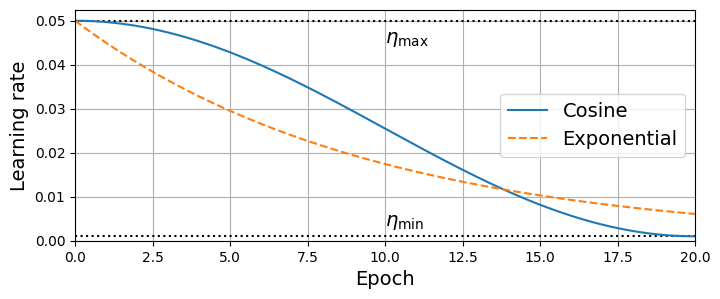

In [76]:
t = np.linspace(0, 20, 400)
eta_min = 0.001
eta_max = 0.05
t2 = 20
eta_cos_t = eta_min + 0.5 * (eta_max - eta_min) * (1 + np.cos(t / t2 * np.pi))
eta_exp_t = 0.9 ** t * eta_max

plt.figure(figsize=(8, 3))
plt.hlines([eta_min, eta_max], 0, 20, color="k", linestyle="dotted")
plt.plot(t, eta_cos_t, label="Cosine")
plt.plot(t, eta_exp_t, "--", label="Exponential")
plt.legend(loc="center right")
plt.text(10, eta_min + 0.0025, r"$\eta_\text{min}$")
plt.text(10, eta_max - 0.005, r"$\eta_\text{max}$")
plt.axis([0, 20, 0, eta_max * 1.05])
plt.grid(True)
plt.xlabel("Epoch")
plt.ylabel("Learning rate")
plt.show()

In [78]:
model = build_model()  # extra code
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)  # or any other optim.
cosine_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=20, eta_min=0.001)

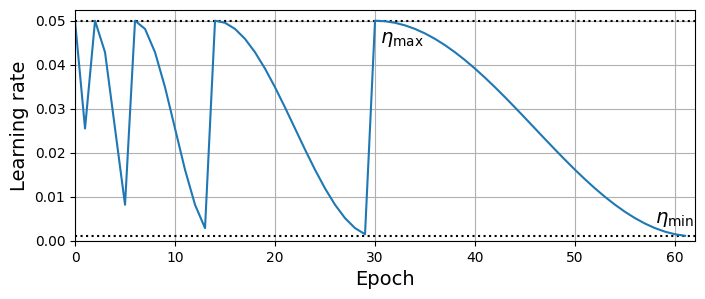

In [79]:
model = build_model()  # extra code
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)  # or any other optim.
cosine_repeat_scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
    optimizer, T_0=2, T_mult=2, eta_min=0.001)

lrs = []
for epoch in range(62):
    lrs.append(cosine_repeat_scheduler.get_last_lr()[0])
    cosine_repeat_scheduler.step()

plt.figure(figsize=(8, 3))
plt.hlines([eta_min, eta_max], 0, 64, color="k", linestyle="dotted")
plt.plot(lrs, label="Cosine")
plt.text(30.5, eta_max - 0.005, r"$\eta_\text{max}$")
plt.text(58, eta_min + 0.003, r"$\eta_\text{min}$")
plt.axis([0, 62, 0, eta_max * 1.05])
plt.grid(True)
plt.xlabel("Epoch")
plt.ylabel("Learning rate")
plt.show()

In [77]:
import re

DOCS_URL = "https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler"
for name in sorted(dir(torch.optim.lr_scheduler)):
    scheduler = getattr(torch.optim.lr_scheduler, name)
    if (not name.startswith("_") and isinstance(scheduler, type) and
        issubclass(scheduler, torch.optim.lr_scheduler.LRScheduler)):
            print(f"• {DOCS_URL}.{name}.html")

• https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.ChainedScheduler.html
• https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.ConstantLR.html
• https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.CosineAnnealingLR.html
• https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.CosineAnnealingWarmRestarts.html
• https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.CyclicLR.html
• https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.ExponentialLR.html
• https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.LRScheduler.html
• https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.LambdaLR.html
• https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.LinearLR.html
• https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.MultiStepLR.html
• https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.MultiplicativeLR.html
• https://pytorch.org/docs/sta

100%|██████████| 26.4M/26.4M [00:02<00:00, 9.60MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 137kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 2.57MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 14.5MB/s]


Epoch 01/62 | Loss: 1.3090 | Test accuracy: 0.7023 | LR: 0.05000
Epoch 02/62 | Loss: 0.7058 | Test accuracy: 0.7583 | LR: 0.02550
Epoch 03/62 | Loss: 0.6394 | Test accuracy: 0.7865 | LR: 0.05000
Epoch 04/62 | Loss: 0.5527 | Test accuracy: 0.8037 | LR: 0.04282
Epoch 05/62 | Loss: 0.5051 | Test accuracy: 0.8126 | LR: 0.02550
Epoch 06/62 | Loss: 0.4879 | Test accuracy: 0.8135 | LR: 0.00818
Epoch 07/62 | Loss: 0.5107 | Test accuracy: 0.8116 | LR: 0.05000
Epoch 08/62 | Loss: 0.4785 | Test accuracy: 0.8047 | LR: 0.04814
Epoch 09/62 | Loss: 0.4574 | Test accuracy: 0.8163 | LR: 0.04282
Epoch 10/62 | Loss: 0.4400 | Test accuracy: 0.8295 | LR: 0.03488
Epoch 11/62 | Loss: 0.4276 | Test accuracy: 0.8347 | LR: 0.02550
Epoch 12/62 | Loss: 0.4197 | Test accuracy: 0.8382 | LR: 0.01612
Epoch 13/62 | Loss: 0.4147 | Test accuracy: 0.8383 | LR: 0.00818
Epoch 14/62 | Loss: 0.4119 | Test accuracy: 0.8399 | LR: 0.00286
Epoch 15/62 | Loss: 0.4407 | Test accuracy: 0.8349 | LR: 0.05000
Epoch 16/62 | Loss: 0.421

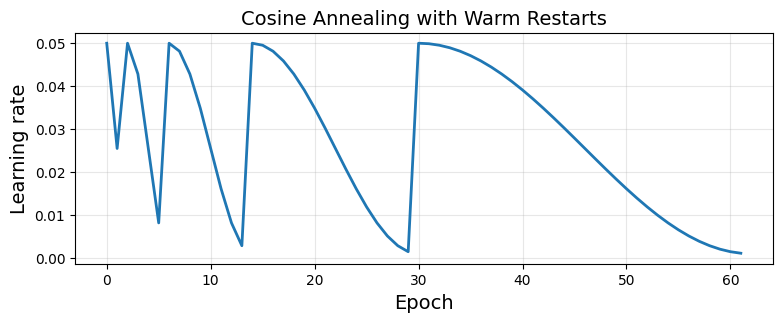

In [80]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

# 1. Device and dataset
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

transform = transforms.ToTensor()

train_set = datasets.FashionMNIST(
    root="./data", train=True, download=True, transform=transform
)
test_set = datasets.FashionMNIST(
    root="./data", train=False, download=True, transform=transform
)

train_loader = DataLoader(train_set, batch_size=256, shuffle=True)
test_loader = DataLoader(test_set, batch_size=256)

# 2. Build the model
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 100),
    nn.ReLU(),
    nn.Linear(100, 100),
    nn.ReLU(),
    nn.Linear(100, 10)
).to(device)

# 3. Optimizer and cosine annealing with warm restarts
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)
loss_fn = nn.CrossEntropyLoss()

scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
    optimizer,
    T_0=2,
    T_mult=2,
    eta_min=0.001
)

# 4. Train for 62 epochs
n_epochs = 62
history = {"train_loss": [], "test_accuracy": [], "lr": []}

for epoch in range(n_epochs):
    model.train()
    total_loss = 0.0

    # Record the LR used during this epoch
    history["lr"].append(optimizer.param_groups[0]["lr"])

    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        optimizer.zero_grad()
        predictions = model(X_batch)
        loss = loss_fn(predictions, y_batch)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * X_batch.size(0)

    train_loss = total_loss / len(train_loader.dataset)
    history["train_loss"].append(train_loss)

    # Evaluate accuracy
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            predictions = model(X_batch)
            correct += (predictions.argmax(dim=1) == y_batch).sum().item()
            total += y_batch.size(0)

    accuracy = correct / total
    history["test_accuracy"].append(accuracy)

    print(
        f"Epoch {epoch+1:02d}/{n_epochs} | "
        f"Loss: {train_loss:.4f} | "
        f"Test accuracy: {accuracy:.4f} | "
        f"LR: {history['lr'][-1]:.5f}"
    )

    # Update the scheduler AFTER optimizer steps
    scheduler.step()

# 5. Plot the learning-rate schedule
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(range(n_epochs), history["lr"], linewidth=2)
ax.set_xlabel("Epoch")
ax.set_ylabel("Learning rate")
ax.set_title("Cosine Annealing with Warm Restarts")
ax.grid(alpha=0.3)
plt.show()